In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
import torch
from torchvision import transforms

In [3]:
df = pd.read_csv("../data/processed/image_metadata.csv")
df.head()

,room,style,path,width,height,aspect_ratio
0,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,421,0.560570
1,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,472,0.500000
2,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,236,1.000000
3,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,183,275,0.665455
4,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,251,201,1.248756


In [4]:
sample = df.sample(1).iloc[0]
sample

room                                                      bedroom
style                                                  minimalist
path            C:\Users\Khushi Trivedi\visual-retrieval-syste...
width                                                         236
height                                                        354
aspect_ratio                                             0.666667
Name: 1205, dtype: object

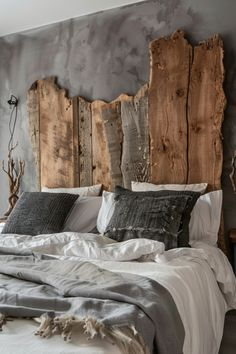

In [5]:
image = Image.open(sample.path)
image

In [6]:
type(image)

PIL.JpegImagePlugin.JpegImageFile

In [7]:
image.size 

(236, 354)

In [8]:
image.mode

'RGB'

In [9]:
image.format 

'JPEG'

In [12]:
image_array = np.array(image) 

In [13]:
type(image_array)

numpy.ndarray

In [14]:
image_array.shape 

(354, 236, 3)

In [15]:
image_array 

array([[[205, 209, 212],
        [205, 209, 212],
        [204, 208, 211],
        ...,
        [ 95,  92,  87],
        [ 95,  92,  87],
        [ 95,  92,  87]],

       [[204, 208, 211],
        [204, 208, 211],
        [204, 208, 211],
        ...,
        [ 96,  93,  88],
        [ 95,  92,  87],
        [ 95,  92,  87]],

       [[204, 208, 211],
        [204, 208, 211],
        [204, 208, 211],
        ...,
        [ 96,  93,  88],
        [ 96,  93,  88],
        [ 95,  92,  87]],

       ...,

       [[207, 211, 212],
        [198, 202, 203],
        [194, 198, 199],
        ...,
        [ 54,  47,  39],
        [ 54,  47,  39],
        [ 55,  48,  40]],

       [[200, 206, 206],
        [200, 206, 206],
        [199, 205, 205],
        ...,
        [ 57,  48,  41],
        [ 58,  49,  42],
        [ 58,  49,  42]],

       [[200, 206, 206],
        [200, 206, 206],
        [199, 205, 205],
        ...,
        [ 58,  49,  42],
        [ 59,  50,  43],
        [ 60,  51,  44]]

In [16]:
image_array[0,0]

array([205, 209, 212], dtype=uint8)

In [17]:
red = image_array[:,:,0]
green = image_array[:,:,1]
blue = image_array[:,:,2]

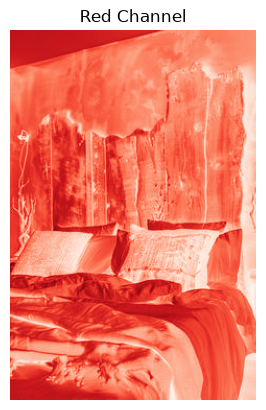

In [18]:
plt.imshow(red, cmap="Reds")
plt.title("Red Channel")
plt.axis("off")
plt.show() 

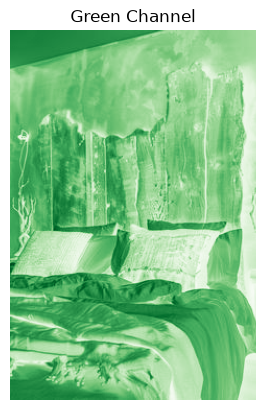

In [19]:
plt.imshow(red, cmap="Greens")
plt.title("Green Channel")
plt.axis("off")
plt.show() 

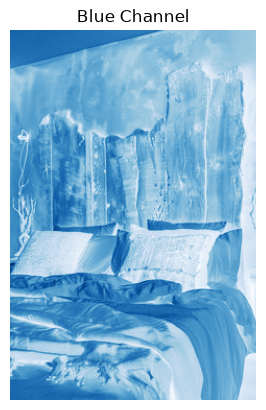

In [20]:
plt.imshow(red, cmap="Blues")
plt.title("Blue Channel")
plt.axis("off")
plt.show() 

In [22]:
image_tensor = torch.tensor(image_array)
image_tensor 

tensor([[[205, 209, 212],
         [205, 209, 212],
         [204, 208, 211],
         ...,
         [ 95,  92,  87],
         [ 95,  92,  87],
         [ 95,  92,  87]],

        [[204, 208, 211],
         [204, 208, 211],
         [204, 208, 211],
         ...,
         [ 96,  93,  88],
         [ 95,  92,  87],
         [ 95,  92,  87]],

        [[204, 208, 211],
         [204, 208, 211],
         [204, 208, 211],
         ...,
         [ 96,  93,  88],
         [ 96,  93,  88],
         [ 95,  92,  87]],

        ...,

        [[207, 211, 212],
         [198, 202, 203],
         [194, 198, 199],
         ...,
         [ 54,  47,  39],
         [ 54,  47,  39],
         [ 55,  48,  40]],

        [[200, 206, 206],
         [200, 206, 206],
         [199, 205, 205],
         ...,
         [ 57,  48,  41],
         [ 58,  49,  42],
         [ 58,  49,  42]],

        [[200, 206, 206],
         [200, 206, 206],
         [199, 205, 205],
         ...,
         [ 58,  49,  42],
        

In [23]:
type(image_tensor)

torch.Tensor

In [24]:
torch.Tensor

torch.Tensor

In [25]:
image_tensor.shape 

torch.Size([354, 236, 3])

In [26]:
image_tensor.min(), image_tensor.max()

(tensor(0, dtype=torch.uint8), tensor(255, dtype=torch.uint8))

In [27]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

In [28]:
processed_image = transform(image)

In [29]:
type(processed_image) 

torch.Tensor

In [30]:
processed_image.shape 

torch.Size([3, 224, 224])

In [32]:
processed_image.min(), processed_image.max()

(tensor(0.), tensor(0.9451))

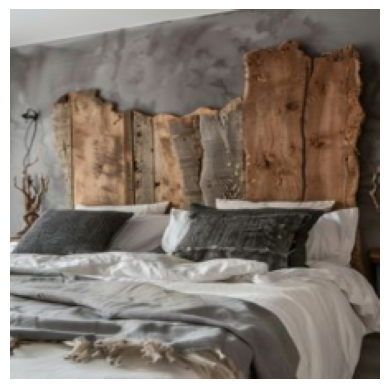

In [33]:
plt.imshow(processed_image.permute(1,2,0))
plt.axis("off")
plt.show()

In [34]:
processed_image.shape 

torch.Size([3, 224, 224])

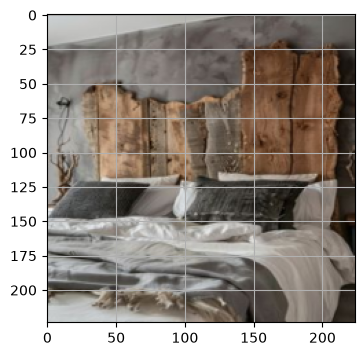

In [35]:
plt.figure(figsize=(4,4))
plt.imshow(processed_image.permute(1,2,0))
plt.axis("on")
plt.grid()

In [37]:
transform_normalized = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.48145466,0.457827,0.40821073],
        std=[0.26862954,0.26130258,0.27577711]
    )
])

In [39]:
normalized_image = transform_normalized(image)

In [42]:
normalized_image.min()

tensor(-1.7777)

In [43]:
normalized_image.max()

tensor(1.9184)

In [44]:
normalized_image.mean()

tensor(-0.0415)